# Chapter 17 — LLM 기반 로그 해석 · 프롬프트 엔지니어링 (실습)

> **주의**: 실제 Claude API 호출에는 API key 가 필요하다 (https://console.anthropic.com).
> 본 실습은 키가 있으면 실제 호출, 없으면 모의 응답으로 진행.

## 실습 목표
1. Claude API 첫 호출
2. 시스템 프롬프트 + JSON 출력
3. 50건 일괄 분류
4. ML 1차 + LLM 2차 하이브리드
5. Prompt caching 비용 비교

> **참고 — Part IV 모델 티어 선택**
>
> 태스크에 맞춰 모델을 나눠 쓴다. 분류처럼 대량·정형 작업은 저비용 **Haiku**,
> RAG 해석·Agent 추론처럼 판단이 무거운 작업은 **Sonnet 5·Opus 4.8**.
> 단 현행 SDK 와 최신 모델은 `temperature`·`top_p`·`top_k` 를 받지 않는다. 호출에서 생략하며,
> 같은 입력에 같은 출력을 보장하는 설정은 없다고 보고 설계한다.

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q anthropic
# !pip install -q pandas
# !pip install -q numpy

In [2]:
import os, json, re, time
import numpy as np
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

# --- API 키 로드: 환경변수 → 루트 .env → Colab Secrets → getpass (없으면 mock 자동) ---
LLM_MODE = os.environ.get('BOOK_LLM_MODE', 'auto')
if LLM_MODE != 'mock':
    if not os.environ.get('ANTHROPIC_API_KEY'):
        from pathlib import Path as _P
        for _d in [_P.cwd(), *_P.cwd().parents]:
            _e = _d / '.env'
            if _e.exists():
                for _l in _e.read_text(encoding='utf-8').splitlines():
                    if _l.strip().startswith('ANTHROPIC_API_KEY='):
                        os.environ['ANTHROPIC_API_KEY'] = _l.split('=', 1)[1].strip().strip('"').strip("'")
                break
        if not os.environ.get('ANTHROPIC_API_KEY'):
            try:
                from google.colab import userdata
                os.environ['ANTHROPIC_API_KEY'] = userdata.get('ANTHROPIC_API_KEY')
            except Exception:
                pass
        if not os.environ.get('ANTHROPIC_API_KEY'):
            try:  # 대화형(Jupyter/Colab)에서만 입력받는다. Enter 만 치면 mock 으로 진행.
                import getpass
                os.environ['ANTHROPIC_API_KEY'] = getpass.getpass('ANTHROPIC_API_KEY (Enter=mock): ') or ''
            except Exception:
                pass
API_KEY = os.environ.get('ANTHROPIC_API_KEY') if os.environ.get('BOOK_LLM_MODE') != 'mock' else None  # Colab Secrets 또는 환경변수
USE_REAL_API = bool(API_KEY)

if USE_REAL_API:
    import anthropic
    client = anthropic.Anthropic(api_key=API_KEY)
    print('Real API mode')
else:
    print('Mock mode (API key 없음)')

Mock mode (API key 없음)


In [3]:
# === 한글 폰트 설정 (matplotlib) ===
# 그래프에서 한글이 깨지면(사각형 □) 아래 설치 명령의 주석을 1회 해제해 실행한 뒤 런타임을 재시작한다.
#   Colab / Ubuntu:  !apt-get install -y fonts-noto-cjk fonts-nanum > /dev/null 2>&1
#   pip 대안       :  !pip install koreanize-matplotlib -q   →   import koreanize_matplotlib
# Windows(맑은 고딕)·macOS(Apple SD Gothic)는 대개 한글 폰트가 기본 설치돼 있어 추가 설치가 필요 없다.
import os
import matplotlib
from matplotlib import font_manager

# OS별로 설치돼 있을 만한 한글 폰트 파일을 모두 등록 시도한다(Noto·나눔·맑은고딕·굴림·Apple 등).
for _fp in [
    # Linux
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf',
    # Windows
    'C:/Windows/Fonts/malgun.ttf', 'C:/Windows/Fonts/malgunbd.ttf',
    'C:/Windows/Fonts/gulim.ttc', 'C:/Windows/Fonts/batang.ttc',
    # macOS
    '/System/Library/Fonts/AppleSDGothicNeo.ttc',
    '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    '/Library/Fonts/AppleGothic.ttf',
]:
    if os.path.exists(_fp):
        try:
            font_manager.fontManager.addfont(_fp)
        except Exception:
            pass

# 등록된 폰트 중 사용 가능한 한글 폰트를 우선순위대로 선택한다.
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _name in ['Malgun Gothic', '맑은 고딕', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans KR',
              'Apple SD Gothic Neo', 'AppleGothic', 'NanumBarunGothic', 'Gulim', 'Batang',
              'Noto Sans CJK JP']:
    if _name in _avail:
        matplotlib.rcParams['font.family'] = _name
        break
matplotlib.rcParams['axes.unicode_minus'] = False  # 한글 폰트에서 마이너스 기호 깨짐 방지


---
## Step 1. 시스템 프롬프트 설정

In [4]:
SYSTEM_PROMPT = '''당신은 SOC 의 senior security analyst 다.
입력 로그를 분석하고 다음 JSON 으로만 응답한다.
{
  "summary": "한 문장 요약",
  "threat_category": "BENIGN|SQLi|XSS|DDoS|PortScan|Brute|Other",
  "severity": 1-5 정수,
  "indicators": ["근거 필드"],
  "recommended_actions": ["대응 1~3"]
}
규칙: 확신 없으면 UNKNOWN, severity=1. 로그에 없는 IP·도메인을 만들지 말 것.'''
print(f'system prompt length = {len(SYSTEM_PROMPT)} chars')

system prompt length = 301 chars


---
## Step 2. 합성 로그 50건

In [5]:
rng = np.random.default_rng(42)
logs = []
for _ in range(30):
    logs.append({'src': f'10.0.0.{rng.integers(1,50)}', 'method': 'GET',
                 'url': rng.choice(['/index.html', '/products', '/api/v1/users']),
                 'ua': 'Mozilla/5.0', 'status': 200})
for _ in range(10):
    logs.append({'src': '10.0.0.99', 'method': 'POST',
                 'url': rng.choice(["/login?id=' OR 1=1--", '/search?q=<script>alert(1)</script>',
                                     '/../etc/passwd', '/login?id=1 UNION SELECT *']),
                 'ua': rng.choice(['sqlmap/1.5', 'nikto/2.1', 'curl/7.0']),
                 'status': rng.choice([401, 403, 500])})
for _ in range(10):
    logs.append({'src': f'192.168.1.{rng.integers(100,200)}', 'method': 'GET',
                 'url': f'/login?attempt={rng.integers(1,100)}',
                 'ua': 'Mozilla/5.0', 'status': 401})
print(f'총 {len(logs)} 건')
logs[:3]

총 50 건


[{'src': '10.0.0.5',
  'method': 'GET',
  'url': np.str_('/api/v1/users'),
  'ua': 'Mozilla/5.0',
  'status': 200},
 {'src': '10.0.0.33',
  'method': 'GET',
  'url': np.str_('/products'),
  'ua': 'Mozilla/5.0',
  'status': 200},
 {'src': '10.0.0.22',
  'method': 'GET',
  'url': np.str_('/api/v1/users'),
  'ua': 'Mozilla/5.0',
  'status': 200}]

---
## Step 3. 분류 함수 — 실제 API 또는 모의 응답

In [6]:
def mock_classify(log: dict) -> dict:
    """API 키 없을 때 룰 기반 mock."""
    url, ua = log.get('url', ''), log.get('ua', '')
    if re.search(r'union|select|or\s+1=1', url, re.I):
        return {'summary':'SQLi pattern','threat_category':'SQLi','severity':4,
                'indicators':['url SQL keyword'],'recommended_actions':['block src']}
    if re.search(r'<script>|javascript:', url, re.I):
        return {'summary':'XSS pattern','threat_category':'XSS','severity':4,
                'indicators':['url script'],'recommended_actions':['block src']}
    if '../' in url:
        return {'summary':'Path traversal','threat_category':'Other','severity':3,
                'indicators':['../'],'recommended_actions':['WAF rule']}
    if re.search(r'sqlmap|nikto', ua, re.I):
        return {'summary':'Suspicious UA','threat_category':'Brute','severity':3,
                'indicators':['UA'],'recommended_actions':['block src']}
    return {'summary':'normal traffic','threat_category':'BENIGN','severity':1,
            'indicators':[],'recommended_actions':[]}

def parse_classification(text, category_key):
    unknown = {category_key: 'UNKNOWN', 'severity': None, 'summary': '검토 필요',
               'reasoning': '응답 형식 검증 실패', 'recommended_actions': []}
    try:
        match = re.fullmatch(r'\s*```(?:json)?\s*(.*?)\s*```\s*', text, re.S)
        result = json.loads(match.group(1) if match else text)
        if not isinstance(result, dict):
            return unknown
        category = result.get(category_key)
        if not isinstance(category, str) or category not in {
                'BENIGN', 'SQLi', 'XSS', 'DDoS', 'PortScan', 'Brute', 'Other', 'UNKNOWN'}:
            return unknown
        severity = result.get('severity')
        if category == 'UNKNOWN':
            return unknown
        if type(severity) is not int or not 1 <= severity <= 5:
            return unknown
        for key in ('summary', 'reasoning'):
            if key in result and not isinstance(result[key], str):
                return unknown
        for key in ('indicators', 'attack_techniques', 'recommended_actions'):
            if key in result and (not isinstance(result[key], list) or
                                  not all(isinstance(item, str) for item in result[key])):
                return unknown
        return result
    except (ValueError, TypeError):
        return unknown

def real_classify(log: dict) -> dict:
    try:
        resp = client.messages.create(
            model='claude-haiku-4-5',
            max_tokens=512,
            system=[{'type':'text','text':SYSTEM_PROMPT,
                     'cache_control':{'type':'ephemeral'}}],
            messages=[{'role':'user','content':f'로그: {json.dumps(log, default=str)}'}],
        )
        text = next((b.text for b in resp.content if getattr(b, "type", None) == "text"), "")
        return parse_classification(text, 'threat_category')
    except Exception:
        return parse_classification('', 'threat_category')

classify = real_classify if USE_REAL_API else mock_classify

In [7]:
# 50건 일괄 분류 (병렬)
start = time.time()
if USE_REAL_API:
    with ThreadPoolExecutor(max_workers=5) as ex:
        results = list(ex.map(classify, logs))
else:
    results = [classify(log) for log in logs]
elapsed = time.time() - start

df = pd.DataFrame([{**log, **r} for log, r in zip(logs, results)])
print(f'분류 완료: {len(df)} 건 in {elapsed:.1f}s')
print('\n--- 위협 카테고리 분포 ---')
print(df['threat_category'].value_counts())
df.head()

분류 완료: 50 건 in 0.0s

--- 위협 카테고리 분포 ---
threat_category
BENIGN    40
XSS        5
SQLi       3
Other      2
Name: count, dtype: int64


,src,method,url,ua,status,summary,threat_category,severity,indicators,recommended_actions
0,10.0.0.5,GET,/api/v1/users,Mozilla/5.0,200,normal traffic,BENIGN,1,[],[]
1,10.0.0.33,GET,/products,Mozilla/5.0,200,normal traffic,BENIGN,1,[],[]
2,10.0.0.22,GET,/api/v1/users,Mozilla/5.0,200,normal traffic,BENIGN,1,[],[]
3,10.0.0.5,GET,/api/v1/users,Mozilla/5.0,200,normal traffic,BENIGN,1,[],[]
4,10.0.0.10,GET,/index.html,Mozilla/5.0,200,normal traffic,BENIGN,1,[],[]


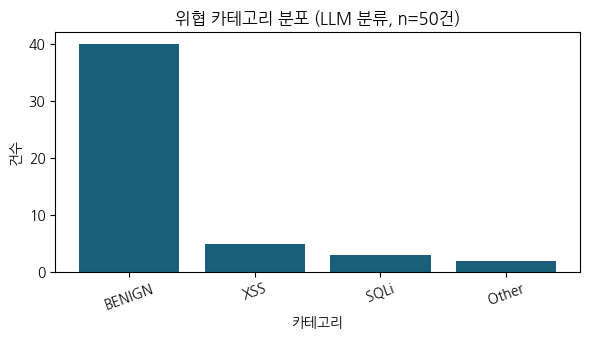

In [8]:
# 위협 카테고리 분포 시각화
import matplotlib.pyplot as plt
vc = df['threat_category'].value_counts()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(vc.index.astype(str), vc.values, color='#1a5f7a')
ax.set_title(f'위협 카테고리 분포 (LLM 분류, n={len(df)}건)')
ax.set_xlabel('카테고리'); ax.set_ylabel('건수')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

---
## Step 4. ML 1차 + LLM 2차 하이브리드 시뮬레이션

In [9]:
# ML 1차 — 단순 룰 기반 확률 mock
def ml_score(log: dict) -> float:
    url, ua = log.get('url',''), log.get('ua','')
    if re.search(r'union|select|<script>|\.\./', url, re.I): return 0.95
    if re.search(r'sqlmap|nikto', ua, re.I):              return 0.85
    if log.get('status') == 401:                           return 0.45
    return 0.05

rows = []
for log in logs:
    s = ml_score(log)
    if s < 0.3:
        rows.append({'log': log['url'], 'ml': s, 'route': 'BENIGN-pass', 'llm': None})
    elif s > 0.7:
        rows.append({'log': log['url'], 'ml': s, 'route': 'ATTACK-instant', 'llm': None})
    else:
        r = classify(log)
        rows.append({'log': log['url'], 'ml': s, 'route': 'LLM-2nd', 'llm': r.get('threat_category')})

routing = pd.DataFrame(rows)
print('--- 라우팅 분포 ---')
print(routing['route'].value_counts())
print('\n--- LLM 2nd 호출 결과 ---')
routing[routing['route']=='LLM-2nd'].head()

--- 라우팅 분포 ---
route
BENIGN-pass       30
ATTACK-instant    10
LLM-2nd           10
Name: count, dtype: int64

--- LLM 2nd 호출 결과 ---


,log,ml,route,llm
40,/login?attempt=80,0.45,LLM-2nd,BENIGN
41,/login?attempt=39,0.45,LLM-2nd,BENIGN
42,/login?attempt=29,0.45,LLM-2nd,BENIGN
43,/login?attempt=68,0.45,LLM-2nd,BENIGN
44,/login?attempt=14,0.45,LLM-2nd,BENIGN


---
## 캐싱 실측 — 긴 시스템 프롬프트일 때만 효과

`cache_control` 은 시스템 프롬프트가 캐시 최소 길이(측정상 Haiku 약 4천 토큰) 이상일 때만 동작한다.
앞의 분류용 프롬프트(약 190 토큰)는 짧아 캐시가 안 걸린다. 아래는 실제 SOC 수준의 긴 룰북을 붙여
캐시를 발동시키고, 2회 호출의 토큰 사용량으로 절감을 실측한다(캐시 읽기 단가 ≈ 입력 단가의 10%).

In [10]:
# 캐시 발동 최소 길이를 넘기기 위한 긴 시스템 프롬프트 = 짧은 지침 + 상세 룰북
RUBRIC = "\n".join([
    "[상세 분류 룰북 — SOC 보안 로그 판정 기준]",
    "아래 카테고리별 정의·주요 지표·대표 예시·오탐(false positive) 주의·권장 대응을 참고해",
    "입력 로그를 일관된 기준으로 분류한다. 확신이 낮으면 항상 보수적으로 BENIGN, severity=1 로 둔다.",
    "",
    "[1] SQLi (SQL Injection)",
    "- 정의: 사용자 입력이 SQL 질의에 그대로 이어붙어 질의 구조가 바뀌는 공격.",
    "- 주요 지표: union select, or 1=1, and 1=1, 주석(--, #, /* */), 따옴표 탈출('), 세미콜론 다중 질의,",
    "  time-based(sleep, benchmark, waitfor delay), boolean-based, error-based, URL 인코딩(%27, %20, %2f),",
    "  sqlmap 계열 User-Agent.",
    "- 대표 예시: /login?id=' OR 1=1--, /item?id=1 UNION SELECT username,password FROM users",
    "- 오탐 주의: 정상 검색어에 select/or/and 단어가 우연히 포함되는 경우, 정상 정렬 파라미터.",
    "- 권장 대응: 해당 src 차단, WAF 규칙 강화, 파라미터 바인딩(Prepared Statement) 점검, 관련 PCAP 수집.",
    "",
    "[2] XSS (Cross-Site Scripting)",
    "- 정의: 악성 스크립트가 다른 사용자의 브라우저에서 실행되도록 삽입되는 공격.",
    "- 주요 지표: <script>, </script>, onerror=, onload=, onmouseover=, javascript:, <svg/onload=,",
    "  <img src=x onerror=, document.cookie, alert(, 대소문자 혼합(<ScRiPt>), HTML/속성 컨텍스트 이스케이프.",
    "- 대표 예시: /?q=<script>alert(document.cookie)</script>, /?x=<svg/onload=alert(1)>",
    "- 오탐 주의: 코드 공유/마크다운 게시판의 정상 태그, 보안 교육용 페이로드 예시 페이지.",
    "- 권장 대응: 출력 인코딩(escape) 점검, CSP 헤더 적용, 입력 정규화, 해당 요청 차단.",
    "",
    "[3] DDoS / DoS (서비스 거부)",
    "- 정의: 대량 트래픽·자원 고갈로 정상 서비스를 마비시키는 공격.",
    "- 주요 지표: 초당 수백~수천 요청, 동일 src 의 급증, 동일 경로 반복 폭주, 비정상 메서드 반복,",
    "  HTTP/2 Rapid Reset(HEADERS 직후 RST_STREAM 폭주), Slowloris(느린 헤더 전송), 증폭 반사 트래픽.",
    "- 대표 예시: 1초에 500회 POST /api/v1/login, 동일 IP 의 초당 수천 SYN.",
    "- 오탐 주의: 이벤트·세일로 인한 정상 트래픽 스파이크, CDN·모니터링 헬스체크, 배치 작업.",
    "- 권장 대응: rate limit, 자동 스케일/차단, 상류 ISP·CDN 협조, HTTP/2 동시 스트림 제한.",
    "",
    "[4] PortScan (포트/호스트 스캐닝)",
    "- 정의: 열린 포트·서비스·취약점을 찾기 위한 정찰 활동.",
    "- 주요 지표: 짧은 시간 다수 포트/호스트 접속, SYN 스캔(half-open), 순차·무작위 포트 증가,",
    "  비정상 TCP 플래그 조합(NULL/FIN/XMAS), nmap/masscan 시그니처.",
    "- 대표 예시: 동일 src 가 1분 내 1000개 포트에 SYN 전송.",
    "- 오탐 주의: 인가된 자산 스캐너·모니터링 에이전트의 정기 점검, 취약점 관리 솔루션.",
    "- 권장 대응: 스캔 원점 차단, 노출 포트 최소화, 자산 인벤토리 대조로 인가 여부 확인.",
    "",
    "[5] Brute / Credential Stuffing (인증 무차별 대입)",
    "- 정의: 비밀번호·키를 반복 추측하거나 유출 자격증명을 대입하는 공격.",
    "- 주요 지표: 짧은 시간 다수 인증 실패(401/403), 동일 계정 반복 시도, 다수 계정 순회,",
    "  공격 도구 UA(hydra, medusa, sqlmap, nikto), 분산 IP 에서의 동시 로그인 시도.",
    "- 대표 예시: 5분 내 동일 IP 의 20회 ssh 인증 실패, 유출 계정 목록 대입.",
    "- 오탐 주의: 사용자의 단순 비밀번호 오타 반복, 만료된 세션 재시도, 모바일 앱 토큰 갱신.",
    "- 권장 대응: 계정 잠금, rate limit, MFA 적용, 비정상 로그인 위치·시간 탐지.",
    "",
    "[6] Other (기타 의심)",
    "- 정의: 위 카테고리에 정확히 속하지 않으나 명백히 의심스러운 활동.",
    "- 주요 지표: 경로 순회(../, ..%2f, /etc/passwd, win.ini), 명령 삽입(;whoami, |id, `cmd`),",
    "  안전하지 않은 역직렬화(pickle, ObjectInputStream), SSRF(내부 IP·메타데이터 169.254.169.254),",
    "  비정상 대용량 업로드, 웹셸 업로드 시도.",
    "- 대표 예시: /download?file=../../../../etc/passwd, /fetch?url=http://169.254.169.254/",
    "- 오탐 주의: 정상 파일 다운로드의 상대 경로, 내부 서비스 간 정상 호출.",
    "- 권장 대응: 입력 검증·정규화, 경로/URL 화이트리스트, 해당 요청 격리·분석.",
    "",
    "[7] BENIGN (정상)",
    "- 정의: 명확한 악성 지표가 없는 정상 트래픽.",
    "- 판정 원칙: 위 어떤 카테고리의 지표도 뚜렷하지 않으면 BENIGN, severity=1 로 판정한다.",
    "- 오탐 관리: 정상을 공격으로 오판하면 운영 피로와 신뢰 저하를 초래하므로, 확신이 낮으면 등급을 낮춘다.",
    "",
    "[공통 규칙]",
    "- 로그에 실제로 존재하는 필드만 근거(indicators)로 인용한다. 없는 IP·도메인·CVE·계정을 지어내지 않는다.",
    "- severity 는 영향 범위와 확신도를 함께 반영한다(1 정보성 ~ 5 즉시 대응 필요).",
    "- recommended_actions 는 실행 가능한 1~3개(차단·격리·티켓 생성·PCAP 수집·룰 추가 등)로 제한한다.",
    "- 확신이 낮은 고위험 판정은 등급을 낮추고 사람 검토(HITL)를 권고한다.",
    "- 하나의 로그가 여러 카테고리 지표를 보이면 가장 심각하고 근거가 분명한 하나로 대표 분류한다."
])
LONG_SYSTEM = SYSTEM_PROMPT + '\n' + RUBRIC * 2   # 약 4.8k 토큰 (캐시 최소 초과)

if USE_REAL_API:
    from anthropic import Anthropic
    _client = Anthropic()
    def _call():
        return _client.messages.create(
            model='claude-haiku-4-5', max_tokens=32,
            system=[{'type': 'text', 'text': LONG_SYSTEM,
                     'cache_control': {'type': 'ephemeral'}}],
            messages=[{'role': 'user', 'content': '로그 분류: {"url": "/", "status": 200}'}]).usage
    u1 = _call(); u2 = _call()
    def g(u, k): return getattr(u, k, 0) or 0
    print(f'1차 호출 — cache_creation={g(u1, "cache_creation_input_tokens")}, cache_read={g(u1, "cache_read_input_tokens")}')
    print(f'2차 호출 — cache_creation={g(u2, "cache_creation_input_tokens")}, cache_read={g(u2, "cache_read_input_tokens")}')
    reused = g(u2, 'cache_read_input_tokens')
    print(f'\n2차에서 캐시로 재사용된 시스템 토큰: {reused} (해당 토큰 입력 비용의 약 90% 절감)')
else:
    print('mock 모드 — real 키로 실행하면 usage 의 cache_read_input_tokens 로 절감이 확인된다.')

mock 모드 — real 키로 실행하면 usage 의 cache_read_input_tokens 로 절감이 확인된다.


---
## 정리
- LLM 으로 보안 로그를 분류·설명·대응 추천까지 한 번에.
- 하이브리드 (ML 빠른 필터 + LLM 모호 케이스 분석) 가 비용·속도·설명 균형.
- Prompt caching 은 긴 시스템 프롬프트를 반복 사용할 때만 절감된다(아래 '캐싱 실측' 참고). 짧은 프롬프트엔 효과가 없다.
- 이어지는 후반부에서 프롬프트 엔지니어링(baseline·CoT·few-shot) 패턴을 실습한다.

---

## (이어서) 프롬프트 엔지니어링 심화와 XAI

> 본 절은 Claude API 기초 위에서 Role·Few-shot·CoT·구조화 출력 4 패턴과 설명 가능성(XAI)·프롬프트 A/B 를 다룬다.



## 실습 목표
1. 4 변형 (baseline / CoT / few-shot / full)
2. 30건 × 4번 호출, 정확도 비교
3. 설명 품질 점수
4. 최고 변형 선정

In [11]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [12]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q anthropic
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib

In [13]:
import os, json, re
import numpy as np
import pandas as pd
API_KEY = os.environ.get('ANTHROPIC_API_KEY') if os.environ.get('BOOK_LLM_MODE') != 'mock' else None
USE_REAL = bool(API_KEY)
if USE_REAL:
    import anthropic
    client = anthropic.Anthropic(api_key=API_KEY)

In [14]:
# 평가용 라벨된 로그 30건 (다양한 카테고리)
rng = np.random.default_rng(42)
labeled = []
for _ in range(10):
    labeled.append(({'src':'10.0.0.5','url':'/index.html','ua':'Mozilla/5.0','status':200}, 'BENIGN'))
for _ in range(7):
    labeled.append(({'src':'10.0.0.99','url':"/login?id=' OR 1=1--",'ua':'sqlmap/1.5','status':401}, 'SQLi'))
for _ in range(7):
    labeled.append(({'src':'10.0.0.99','url':'/?q=<script>alert(1)</script>','ua':'curl','status':200}, 'XSS'))
for _ in range(6):
    labeled.append(({'src':'192.168.1.50','url':'/login','ua':'Mozilla/5.0','status':401}, 'Brute'))
rng.shuffle(labeled)
print(f'총 {len(labeled)} 건')

총 30 건


---
## Step 1. 4가지 프롬프트 변형

In [15]:
BASELINE = '''당신은 보안 분석가. 로그를 분류한다.
{"category": "BENIGN|SQLi|XSS|DDoS|Brute|Other", "severity":1-5, "reasoning":"..."}'''

COT = BASELINE + '\n\n반드시 단계별 추론:\n1. 핵심 필드 식별\n2. 베이스라인 비교\n3. 패턴 매칭\n4. 결론'

EXAMPLES = '''
예시 1:
입력: {"url":"/login?id=' OR 1=1--","ua":"sqlmap"}
출력: {"category":"SQLi","severity":4,"reasoning":"SQL keyword + sqlmap UA"}
예시 2:
입력: {"url":"/index.html","ua":"Mozilla"}
출력: {"category":"BENIGN","severity":1,"reasoning":"정상 페이지 요청"}
'''
FEWSHOT = BASELINE + EXAMPLES
FULL = COT + EXAMPLES

PROMPTS = {'baseline': BASELINE, 'CoT': COT, 'few-shot': FEWSHOT, 'full': FULL}

---
## Step 2. 분류 함수 (mock + real)

In [16]:
def mock_classify(log, system):
    url, ua = log.get('url',''), log.get('ua','')
    has_examples = 'few-shot' in system or '예시' in system
    has_cot = 'step' in system.lower() or '단계' in system
    # 더 정교한 프롬프트일수록 mock 정확도 ↑
    if re.search(r'union|select|or\s+1=1', url, re.I):
        cat = 'SQLi'
    elif re.search(r'<script>|javascript:', url, re.I):
        cat = 'XSS'
    elif log.get('status') == 401 and 'login' in url:
        cat = 'Brute' if (has_examples and has_cot) else ('Brute' if has_examples else 'Other')
    else:
        cat = 'BENIGN'
    return {'category': cat, 'severity': 4 if cat!='BENIGN' else 1,
            'reasoning': f'mock based on {url}', 'attack_techniques': [], 'fields_observed': [{'value': url}],
            'recommended_actions': ['block'] if cat!='BENIGN' else []}

def real_classify(log, system):
    try:
        resp = client.messages.create(model='claude-haiku-4-5',
            max_tokens=512, system=system,
            messages=[{'role':'user','content':f'로그: {json.dumps(log, default=str)}'}])
        text = next((b.text for b in resp.content if getattr(b, "type", None) == "text"), "")
        return parse_classification(text, 'category')
    except Exception:
        return parse_classification('', 'category')

classify = real_classify if USE_REAL else mock_classify

---
## Step 3. A/B 평가

baseline   accuracy = 80.00%
CoT        accuracy = 80.00%
few-shot   accuracy = 100.00%
full       accuracy = 100.00%


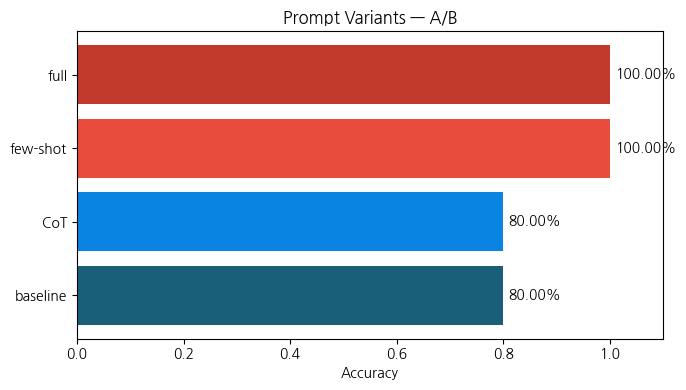

In [17]:
results = {}
for name, sys in PROMPTS.items():
    correct = 0
    for log, truth in labeled:
        r = classify(log, system=sys)
        if r.get('category') == truth:
            correct += 1
    results[name] = correct / len(labeled)
    print(f'{name:10s} accuracy = {results[name]:.2%}')

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(list(results.keys()), list(results.values()),
        color=['#1a5f7a','#0984e3','#e74c3c','#c0392b'])
for i, (k, v) in enumerate(results.items()):
    ax.text(v + 0.01, i, f'{v:.2%}', va='center')
ax.set_xlim(0, 1.1)
ax.set_xlabel('Accuracy'); ax.set_title('Prompt Variants — A/B')
plt.tight_layout(); plt.show()

---
## Step 4. 설명 품질 평가

In [18]:
def eval_explanation(log, analysis):
    analysis = analysis if isinstance(analysis, dict) else {}
    reasoning = analysis.get('reasoning')
    techniques = analysis.get('attack_techniques')
    actions = analysis.get('recommended_actions')
    return {
        'reasoning_length': len(reasoning) if isinstance(reasoning, str) else 0,
        'has_attack_id': isinstance(techniques, list) and any(
            isinstance(item, str) and item.strip() for item in techniques),
        'actionable': isinstance(actions, list) and any(
            isinstance(item, str) and item.strip() for item in actions),
    }

best_prompt = max(results, key=results.get)
rows = []
for log, truth in labeled[:5]:
    a = classify(log, system=PROMPTS[best_prompt])
    rows.append({'log': log['url'], 'truth': truth,
                 'pred': a.get('category'), **eval_explanation(log, a)})
pd.DataFrame(rows)

,log,truth,pred,reasoning_length,has_attack_id,actionable
0,/login,Brute,Brute,20,False,True
1,/login?id=' OR 1=1--,SQLi,SQLi,34,False,True
2,/index.html,BENIGN,BENIGN,25,False,False
3,/login,Brute,Brute,20,False,True
4,/login,Brute,Brute,20,False,True


---
## 정리
- 프롬프트 변형은 같은 표본으로 비교하며, 결합 방식이 항상 우수하지는 않다.
- 설명 길이·기법 ID·대응 필드는 형식 점검이다. 설명의 사실성과 충실성은 근거와 대조한다.
- 다음 ch18에서는 검색 자료를 연결하고 답변의 인용 ID를 검증한다.
- 이전 실제 API 측정(30건)은 기준·few-shot·결합 80.00%, CoT 66.67%였다. 현재 출력의 실행 모드와 구분한다.
